# Definición de CNNs en PyTorch

Notebook introductorio para definir y entrenar una red convolucional (CNN) en PyTorch.

In [1]:
import torch
import torch.nn as nn
from torch.utils.data import DataLoader
from torchvision import datasets, transforms
import matplotlib.pyplot as plt

if torch.cuda.is_available():
    device = torch.device("cuda")
elif torch.backends.mps.is_available():
    device = torch.device("mps")
else:
    device = torch.device("cpu")
print(f"Dispositivo: {device}")

Dispositivo: mps


## 1. Carga de datos

Descargamos Fashion MNIST con `torchvision` y lo normalizamos a \([0, 1]\).

In [2]:
transform = transforms.ToTensor()

train_data = datasets.FashionMNIST(
    root="./data", train=True, download=True, transform=transform
)
test_data = datasets.FashionMNIST(
    root="./data", train=False, download=True, transform=transform
)

train_loader = DataLoader(train_data, batch_size=64, shuffle=True)
test_loader = DataLoader(test_data, batch_size=64, shuffle=False)

class_names = train_data.classes
print(f"Entrenamiento: {len(train_data)} imágenes")
print(f"Prueba: {len(test_data)} imágenes")
print(f"Clases: {class_names}")

Entrenamiento: 60000 imágenes
Prueba: 10000 imágenes
Clases: ['T-shirt/top', 'Trouser', 'Pullover', 'Dress', 'Coat', 'Sandal', 'Shirt', 'Sneaker', 'Bag', 'Ankle boot']


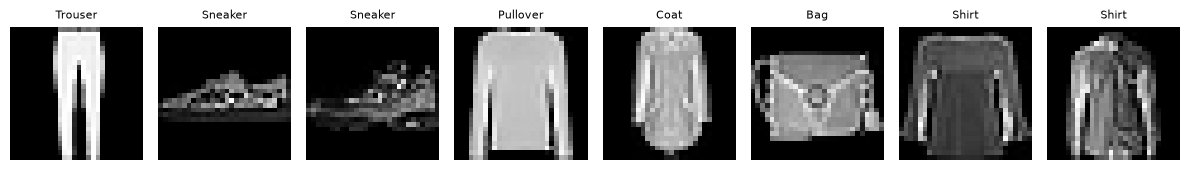

In [3]:
images, labels = next(iter(train_loader))

fig, axes = plt.subplots(1, 8, figsize=(12, 2))
for i, ax in enumerate(axes):
    ax.imshow(images[i].squeeze(), cmap="gray")
    ax.set_title(class_names[labels[i]], fontsize=8)
    ax.axis("off")
plt.tight_layout()
plt.show()

## 2. Definición del modelo

In [4]:
from functools import partial

DefualtConv2d = partial(nn.Conv2d, kernel_size=3, padding="same")
DefaultMaxPool2d = partial(nn.MaxPool2d, kernel_size=2)
class FashionCNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.features = nn.Sequential(
            DefualtConv2d(1, 64, kernel_size=7), #primera convolución suele tener un kernel más grande
            nn.ReLU(),
            DefaultMaxPool2d(),
            DefualtConv2d(64, 128),
            nn.ReLU(),
            DefualtConv2d(128, 128),
            nn.ReLU(),
            DefaultMaxPool2d(),
            DefualtConv2d(128, 256),
            nn.ReLU(),
            DefualtConv2d(256, 256),
            nn.ReLU(),
            DefaultMaxPool2d(),
        )
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.LazyLinear(128), #No necesitamos especificar el tamaño de la entrada, util despues de varios modulos convolucionales
            nn.ReLU(),
            nn.Dropout(0.5),
            nn.Linear(128, 64),
            nn.ReLU(),
            nn.Dropout(0.5),
            nn.Linear(64, 10),
        )

    def forward(self, x):
        x = self.features(x)
        return self.classifier(x)


model = FashionCNN().to(device)
print(model)

FashionCNN(
  (features): Sequential(
    (0): Conv2d(1, 64, kernel_size=(7, 7), stride=(1, 1), padding=same)
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=same)
    (4): ReLU()
    (5): Conv2d(128, 128, kernel_size=(3, 3), stride=(1, 1), padding=same)
    (6): ReLU()
    (7): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (8): Conv2d(128, 256, kernel_size=(3, 3), stride=(1, 1), padding=same)
    (9): ReLU()
    (10): Conv2d(256, 256, kernel_size=(3, 3), stride=(1, 1), padding=same)
    (11): ReLU()
    (12): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): LazyLinear(in_features=0, out_features=128, bias=True)
    (2): ReLU()
    (3): Dropout(p=0.5, inplace=False)
    (4): Linear(in_features=128, out_features=64, bias=True)
  

## 3. Entrenamiento

Usamos entropía cruzada y el optimizador Adam.

In [5]:
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters())

n_epochs = 10

for epoch in range(n_epochs):
    model.train()
    running_loss = 0.0
    correct = 0
    total = 0

    for images, labels in train_loader:
        images, labels = images.to(device), labels.to(device)

        optimizer.zero_grad()
        outputs = model(images)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        running_loss += loss.item() * images.size(0)
        _, predicted = outputs.max(1)
        total += labels.size(0)
        correct += predicted.eq(labels).sum().item()

    epoch_loss = running_loss / total
    epoch_acc = 100.0 * correct / total
    print(f"Época {epoch + 1}/{n_epochs} — pérdida: {epoch_loss:.4f} — exactitud: {epoch_acc:.2f}%")

Época 1/10 — pérdida: 0.7752 — exactitud: 71.62%
Época 2/10 — pérdida: 0.4376 — exactitud: 84.76%
Época 3/10 — pérdida: 0.3683 — exactitud: 87.39%
Época 4/10 — pérdida: 0.3280 — exactitud: 88.78%
Época 5/10 — pérdida: 0.3000 — exactitud: 89.75%
Época 6/10 — pérdida: 0.2760 — exactitud: 90.56%
Época 7/10 — pérdida: 0.2569 — exactitud: 91.17%
Época 8/10 — pérdida: 0.2431 — exactitud: 91.67%
Época 9/10 — pérdida: 0.2260 — exactitud: 92.23%
Época 10/10 — pérdida: 0.2102 — exactitud: 92.70%


## 4. Evaluación

Medimos la exactitud en el conjunto de prueba y visualizamos algunas predicciones.

In [6]:
model.eval()
correct = 0
total = 0

with torch.no_grad():
    for images, labels in test_loader:
        images, labels = images.to(device), labels.to(device)
        outputs = model(images)
        _, predicted = outputs.max(1)
        total += labels.size(0)
        correct += predicted.eq(labels).sum().item()

print(f"Exactitud en prueba: {100.0 * correct / total:.2f}%")

Exactitud en prueba: 91.20%


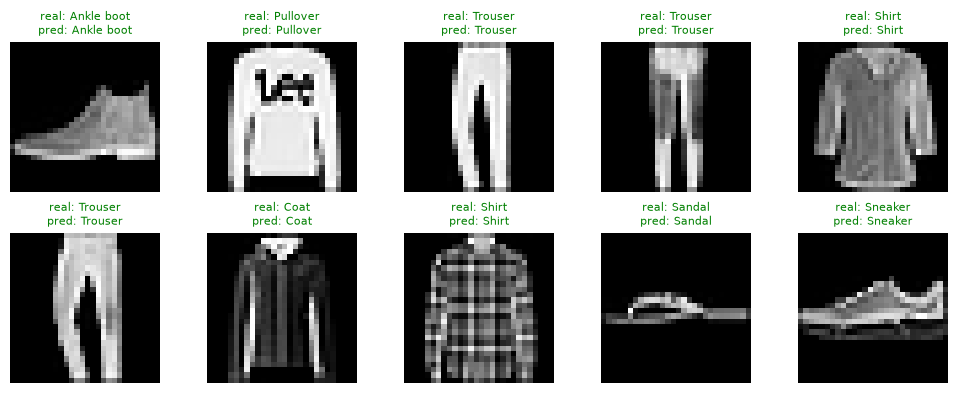

In [7]:
images, labels = next(iter(test_loader))
images, labels = images.to(device), labels.to(device)

with torch.no_grad():
    preds = model(images).argmax(dim=1)

fig, axes = plt.subplots(2, 5, figsize=(10, 4))
for i, ax in enumerate(axes.flat):
    ax.imshow(images[i].cpu().squeeze(), cmap="gray")
    color = "green" if preds[i] == labels[i] else "red"
    ax.set_title(
        f"real: {class_names[labels[i]]}\npred: {class_names[preds[i]]}",
        fontsize=8,
        color=color,
    )
    ax.axis("off")
plt.tight_layout()
plt.show()